In [206]:
import pandas as pd

In [207]:
idb5yr = pd.read_csv('idb5yr.csv')

In [ ]:
idbsingleyear = pd.read_csv('idbsingleyear.csv')

In [41]:
idbsingleyear.dtypes

YR        int64
GEO_ID      str
AGE       int64
SEX       int64
POP       int64
dtype: object

In [42]:
idbsingleyear[(idbsingleyear['SEX'] == 1) & (idbsingleyear['GEO_ID'] == 'W140000WOAD') & (idbsingleyear['YR'] == 1990)]['POP'].sum()

np.int64(27865)

In [208]:
idb5yr[(idb5yr['GEO_ID'] == 'W140000WOAD') & (idb5yr['YR'] == 1990)]['MPOP']

40    27865.0
Name: MPOP, dtype: float64

In [209]:
idb5yr.columns

Index(['YR', 'GEO_ID', 'AREA_KM2', 'ASFR15_19', 'ASFR20_24', 'ASFR25_29',
       'ASFR30_34', 'ASFR35_39', 'ASFR40_44', 'ASFR45_49',
       ...
       'DEATHS', 'NIM', 'NATINCR', 'MEDAGE', 'MEDAGE_M', 'MEDAGE_F',
       'SEXRATIO', 'DEPND', 'DEPND0_14', 'DEPND65_'],
      dtype='str', length=115)

In [210]:
idb5yr['GEO_ID'].unique()

<StringArray>
[            'W140000WOAD',             'W140000WOAE',
             'W140000WOAF',             'W140000WOAG',
             'W140000WOAI',             'W140000WOAL',
             'W140000WOAM',             'W140000WOAO',
             'W140000WOAR',             'W140000WOAS',
 ...
 'W650000WOPK008002001001', 'W650000WOPK008002001002',
 'W650000WOPK008002002001', 'W650000WOPK008003001001',
 'W650000WOPK008003001002', 'W650000WOPK008003001003',
 'W650000WOPK008003002001', 'W650000WOPK008003002002',
 'W650000WOPK008003003001', 'W650000WOPK008003004001']
Length: 13898, dtype: str

In [211]:
idb5yr_nation = idb5yr[idb5yr['GEO_ID'].str[0:3] == 'W14']

In [212]:
idb5yr_nation['GEO_ID'].unique()

<StringArray>
['W140000WOAD', 'W140000WOAE', 'W140000WOAF', 'W140000WOAG', 'W140000WOAI',
 'W140000WOAL', 'W140000WOAM', 'W140000WOAO', 'W140000WOAR', 'W140000WOAS',
 ...
 'W140000WOVU', 'W140000WOWF', 'W140000WOWS', 'W140000WOXG', 'W140000WOXK',
 'W140000WOXW', 'W140000WOYE', 'W140000WOZA', 'W140000WOZM', 'W140000WOZW']
Length: 227, dtype: str

In [213]:
idb5yr_nation['ALPHA2_CODE'] = idb5yr_nation['GEO_ID'].str[9:11]
idb5yr_nation['ALPHA2_CODE'].unique()

/tmp/ipykernel_19367/3237582330.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  idb5yr_nation['ALPHA2_CODE'] = idb5yr_nation['GEO_ID'].str[9:11]


<StringArray>
['AD', 'AE', 'AF', 'AG', 'AI', 'AL', 'AM', 'AO', 'AR', 'AS',
 ...
 'VU', 'WF', 'WS', 'XG', 'XK', 'XW', 'YE', 'ZA', 'ZM', 'ZW']
Length: 227, dtype: str

In [214]:
import pycountry
countries = {}
for country in pycountry.countries:
    countries[country.alpha_2] = country.name

country_map = pd.DataFrame({'ALPHA2_CODE':idb5yr_nation['ALPHA2_CODE'].unique()})
country_map['COUNTRY'] = country_map['ALPHA2_CODE'].map(countries)
country_map[country_map['COUNTRY'].isna()]

,ALPHA2_CODE,COUNTRY
220,XG,NaN
221,XK,NaN
222,XW,NaN


In [215]:
idb5yr_nation['COUNTRY'] = idb5yr_nation['ALPHA2_CODE'].map(countries)
idb5yr_nation.dropna(subset=['COUNTRY'], inplace=True)

/tmp/ipykernel_19367/718503835.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  idb5yr_nation['COUNTRY'] = idb5yr_nation['ALPHA2_CODE'].map(countries)


In [216]:
idb5yr_nation.head(5)

,YR,GEO_ID,AREA_KM2,ASFR15_19,ASFR20_24,ASFR25_29,ASFR30_34,ASFR35_39,ASFR40_44,ASFR45_49,...,NATINCR,MEDAGE,MEDAGE_M,MEDAGE_F,SEXRATIO,DEPND,DEPND0_14,DEPND65_,ALPHA2_CODE,COUNTRY
0,1950,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,Andorra
1,1951,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,Andorra
2,1952,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,Andorra
3,1953,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,Andorra
4,1954,W140000WOAD,468.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AD,Andorra


In [217]:
population_data = idb5yr_nation[['YR', 'GEO_ID', 'AREA_KM2', 'POP_DENS', 'POP']]
population_data.head(5)

,YR,GEO_ID,AREA_KM2,POP_DENS,POP
0,1950,W140000WOAD,468.0,13.2,6176
1,1951,W140000WOAD,468.0,13.5,6310
2,1952,W140000WOAD,468.0,12.5,5866
3,1953,W140000WOAD,468.0,11.9,5591
4,1954,W140000WOAD,468.0,11.8,5503


In [218]:
general_data = idb5yr_nation[['YR', 'GEO_ID', 'NATINCR', 'TFR', 'DEATHS', 'NIM', 'SEXRATIO']]
general_data.dropna(inplace=True)
general_data.head(5)

,YR,GEO_ID,NATINCR,TFR,DEATHS,NIM,SEXRATIO
40,1990,W140000WOAD,334.0,1.2940,294.0,2976.0,1.120
41,1991,W140000WOAD,344.0,1.3171,334.0,3802.0,1.116
42,1992,W140000WOAD,392.0,1.3414,337.0,1957.0,1.111
43,1993,W140000WOAD,398.0,1.2660,325.0,2928.0,1.108
44,1994,W140000WOAD,420.0,1.2083,284.0,-1211.0,1.106


In [219]:
baby_data = idb5yr_nation[['YR', 'GEO_ID', 'SRB', 'IMR', 'E0', 'BIRTHS']]
baby_data.dropna(inplace=True)
baby_data.head(5)

,YR,GEO_ID,SRB,IMR,E0,BIRTHS
40,1990,W140000WOAD,1.13,5.85,79.48,628.0
41,1991,W140000WOAD,0.92,6.83,78.64,678.0
42,1992,W140000WOAD,1.08,6.94,78.34,729.0
43,1993,W140000WOAD,0.98,6.46,79.03,723.0
44,1994,W140000WOAD,1.21,5.20,80.46,704.0


In [220]:
age_data = idb5yr_nation[['YR', 'GEO_ID']]
age_data.head(5)

,YR,GEO_ID
0,1950,W140000WOAD
1,1951,W140000WOAD
2,1952,W140000WOAD
3,1953,W140000WOAD
4,1954,W140000WOAD


In [221]:
age_data['POP_YOUNG'] = idb5yr_nation[['POP0_4', 'POP5_9', 'POP10_14', 'POP15_19', 'POP20_24', 'POP25_29']].sum(axis=1)
age_data['POP_MIDDLE'] = idb5yr_nation[['POP30_34', 'POP35_39', 'POP40_44', 'POP45_49', 'POP50_54', 'POP55_59']].sum(axis=1)
age_data['POP_OLD'] = idb5yr_nation[['POP60_64', 'POP65_69', 'POP70_74', 'POP75_79', 'POP80_84', 'POP85_89', 'POP90_94', 'POP95_99', 'POP100_']].sum(axis=1)
age_data = age_data[['YR', 'GEO_ID', 'POP_YOUNG', 'POP_MIDDLE', 'POP_OLD']]
age_data = age_data[age_data['POP_YOUNG'] > 0]
age_data = age_data[age_data['POP_MIDDLE'] > 0]
age_data = age_data[age_data['POP_OLD'] > 0]
age_data.head(5)

,YR,GEO_ID,POP_YOUNG,POP_MIDDLE,POP_OLD
40,1990,W140000WOAD,23169.0,22264.0,7314.0
41,1991,W140000WOAD,25440.0,23352.0,7683.0
42,1992,W140000WOAD,27240.0,24453.0,8029.0
43,1993,W140000WOAD,28577.0,25622.0,8360.0
44,1994,W140000WOAD,28605.0,26587.0,8634.0


In [222]:
import matplotlib.pyplot as plt

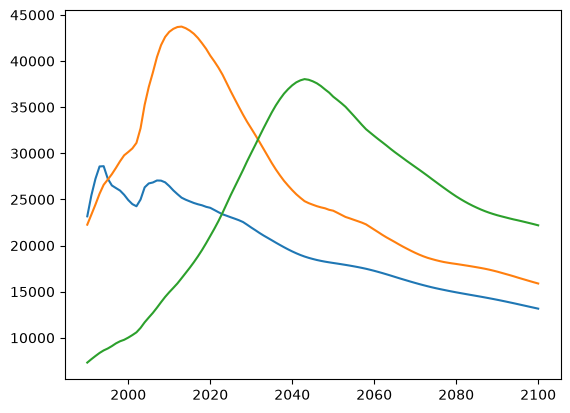

In [223]:
section = age_data[age_data['GEO_ID'] == 'W140000WOAD']
plt.plot(section['YR'], section['POP_YOUNG'])
plt.plot(section['YR'], section['POP_MIDDLE'])
plt.plot(section['YR'], section['POP_OLD'])